In [1]:
import os
print(os.listdir())

['.ipynb_checkpoints', 'master_clean.csv', 'olist_customers_dataset.csv', 'olist_geolocation_dataset.csv', 'olist_orders_dataset.csv', 'olist_order_items_dataset.csv', 'olist_order_payments_dataset.csv', 'olist_order_reviews_dataset.csv', 'olist_outputs', 'olist_products_dataset.csv', 'olist_sellers_dataset.csv', 'product_category_name_translation.csv', 'q10_sellers.png', 'q7_satisfaction.png', 'q8_retention.png', 'q9_rfm_segments.png', 'Untitled.ipynb']


In [2]:
import pandas as pd

orders = pd.read_csv("olist_orders_dataset.csv")
customers = pd.read_csv("olist_customers_dataset.csv")
items = pd.read_csv("olist_order_items_dataset.csv")
payments = pd.read_csv("olist_order_payments_dataset.csv")
reviews   = pd.read_csv("olist_order_reviews_dataset.csv")
products  = pd.read_csv("olist_products_dataset.csv")
sellers   = pd.read_csv("olist_sellers_dataset.csv")
geo       = pd.read_csv("olist_geolocation_dataset.csv")
cat_trans = pd.read_csv("product_category_name_translation.csv")

orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [3]:
tables = {"orders": orders, "customers": customers, "items": items,
          "payments": payments, "reviews": reviews, "products": products,
          "sellers": sellers, "geo": geo, "cat_trans": cat_trans}

for name, df in tables.items():
    print(f"{name}: {df.shape[0]} rows, {df.shape[1]} columns")

orders: 99441 rows, 8 columns
customers: 99441 rows, 5 columns
items: 112650 rows, 7 columns
payments: 103886 rows, 5 columns
reviews: 99224 rows, 7 columns
products: 32951 rows, 9 columns
sellers: 3095 rows, 4 columns
geo: 1000163 rows, 5 columns
cat_trans: 71 rows, 2 columns


In [4]:
for name, df in tables.items():
    print(f"\n=== {name} ===")
    print("Duplicate rows:", df.duplicated().sum())
    missing = df.isna().sum()
    print("Missing values:")
    print(missing[missing > 0] if missing.sum() > 0
           else "None")


=== orders ===
Duplicate rows: 0
Missing values:
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

=== customers ===
Duplicate rows: 0
Missing values:
None

=== items ===
Duplicate rows: 0
Missing values:
None

=== payments ===
Duplicate rows: 0
Missing values:
None

=== reviews ===
Duplicate rows: 0
Missing values:
review_comment_title      87656
review_comment_message    58247
dtype: int64

=== products ===
Duplicate rows: 0
Missing values:
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

=== sellers ===
Duplicate rows: 0
Missing values:
None

=== geo ===
Duplicate rows: 261831
Missing values:
None

=== cat_trans ===
Duplicate rows: 0
Missing values:
None


In [5]:
date_cols =["order_purchase_timestamp", "order_approved_at",
            "order_delivered_carrier_date", "order_delivered_customer_date",
            "order_estimated_delivery_date"]

for c in date_cols:
    orders[c] = pd.to_datetime(orders[c])

orders.dtypes

order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

In [6]:
print(orders["order_status"].value_counts())

missing_delivery = orders[orders["order_delivered_customer_date"].isna()]
print(missing_delivery["order_status"].value_counts())

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64
order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64


In [7]:
print("Reviews total:", len(reviews))
print("Unique order_ids in reviews:", reviews["order_id"].nunique())

Reviews total: 99224
Unique order_ids in reviews: 98673


In [8]:
products["product_category_name"] = products["product_category_name"].fillna("unknown")
geo = geo.drop_duplicates()
print(geo.shape)

(738332, 5)


## Cleaning Decisions Log

- Orders: missing delivery dates are mostly canceled or in-transit orders, so I kept them.
- Reviews: missing comments are normal, so I kept them.
- Products: 610 missing categories were labeled "unknown" instead of deleted.
- Geo: removed 261,831 exact duplicate rows.
- Orders: 8 orders are marked "delivered" but have no delivery date. I will exclude them from delivery-time calculations but keep them for revenue.
- Orders: 6 canceled orders have a delivery date. I will exclude canceled orders from revenue.
- Reviews: 551 orders had more than one review. I kept the most recent review per order.
- Orders: I'll use delivered orders for the delivery and satisfaction analysis.
- Reviews: 551 orders had more than one review. I kept the most recent one per order, so the table now has one row per order (98,673 rows).

In [9]:
reviews["review_answer_timestamp"] = pd.to_datetime(reviews["review_answer_timestamp"])

reviews_clean = (reviews
                 .sort_values("review_answer_timestamp")
                 .drop_duplicates(subset="order_id", keep="last"))

print("Before:", len(reviews), "After:", len(reviews_clean))
print("Unique orders:", reviews_clean["order_id"].nunique())

Before: 99224 After: 98673
Unique orders: 98673


In [10]:
odd = orders[(orders["order_status"] == "delivered") &
             (orders["order_delivered_customer_date"].isna())]
print(len(odd))
odd[["order_id", "order_purchase_timestamp", "order_delivered_carrier_date",
     "order_estimated_delivery_date"]]

8


,order_id,order_purchase_timestamp,order_delivered_carrier_date,order_estimated_delivery_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,2017-11-28 17:44:07,2017-11-30 18:12:23,2017-12-18
20618,f5dd62b788049ad9fc0526e3ad11a097,2018-06-20 06:58:43,2018-06-25 08:05:00,2018-07-16
43834,2ebdfc4f15f23b91474edf87475f108e,2018-07-01 17:05:11,2018-07-03 13:57:00,2018-07-30
79263,e69f75a717d64fc5ecdfae42b2e8e086,2018-07-01 22:05:55,2018-07-03 13:57:00,2018-07-30
82868,0d3268bad9b086af767785e3f0fc0133,2018-07-01 21:14:02,2018-07-03 09:28:00,2018-07-24
92643,2d858f451373b04fb5c984a1cc2defaf,2017-05-25 23:22:43,NaT,2017-06-23
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,2018-06-08 12:09:39,2018-06-12 14:10:00,2018-06-26
98038,20edc82cf5400ce95e1afacc25798b31,2018-06-27 16:09:12,2018-07-03 19:26:00,2018-07-19


In [11]:
items_agg = (items.groupby("order_id")
             .agg(n_items=("order_item_id", "count"),
                  items_value=("price", "sum"),
                  freight_value=("freight_value", "sum"))
             .reset_index())

print(items_agg.shape)
items_agg.head()

(98666, 4)


,order_id,n_items,items_value,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,199.90,18.14


In [12]:
payments_agg = (payments.groupby("order_id")
                .agg(payment_value=("payment_value", "sum"),
                     n_payment_methods=("payment_type", "nunique"))
                .reset_index())

print(payments_agg.shape)
payments_agg.head()

(99440, 3)


,order_id,payment_value,n_payment_methods
0,00010242fe8c5a6d1ba2dd792cb16214,72.19,1
1,00018f77f2f0320c557190d7a144bdd3,259.83,1
2,000229ec398224ef6ca0657da4fc703e,216.87,1
3,00024acbcdf0a6daa1e931b038114c75,25.78,1
4,00042b26cf59d7ce69dfabb4e55b4fd9,218.04,1


In [13]:
master = (orders
          .merge(customers, on="customer_id", how="left")
          .merge(items_agg, on="order_id", how="left")
          .merge(payments_agg, on="order_id", how="left")
          .merge(reviews_clean[["order_id", "review_score"]], on="order_id", how="left"))

print("Orders:", len(orders), " Master:", len(master))
master.head()

Orders: 99441  Master: 99441


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,n_items,items_value,freight_value,payment_value,n_payment_methods,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,1.0,29.99,8.72,38.71,2.0,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,1.0,118.70,22.76,141.46,1.0,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,1.0,159.90,19.22,179.12,1.0,5.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN,1.0,45.00,27.20,72.20,1.0,5.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP,1.0,19.90,8.72,28.62,1.0,5.0


In [14]:
missing = master.isna().sum()
print(missing[missing > 0])

order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
n_items                           775
items_value                       775
freight_value                     775
payment_value                       1
n_payment_methods                   1
review_score                      768
dtype: int64


In [15]:
no_items = master[master["n_items"].isna()]
print(no_items["order_status"].value_counts())

order_status
unavailable    603
canceled       164
created          5
invoiced         2
shipped          1
Name: count, dtype: int64


In [16]:
## Columns needed for the analysis

import numpy as np

master["order_month"] = master["order_purchase_timestamp"].dt.to_period("M").astype(str)

master["delivery_days"] = (master["order_delivered_customer_date"]
                           - master["order_purchase_timestamp"]).dt.total_seconds() / 86400

master["delay_days"] = (master["order_delivered_customer_date"]
                        - master["order_estimated_delivery_date"]).dt.total_seconds() / 86400

master["is_late"] = np.where(master["order_delivered_customer_date"].isna(),
                             np.nan,
                             (master["delay_days"] > 0).astype(float))

master[["order_month", "delivery_days", "delay_days", "is_late"]].describe()

,delivery_days,delay_days,is_late
count,96476.000000,96476.000000,96476.000000
mean,12.558702,-11.179120,0.081129
std,9.546530,10.186113,0.273035
min,0.533414,-146.016123,0.000000
25%,6.766403,-16.244384,0.000000
50%,10.217755,-11.948941,0.000000
75%,15.720327,-6.390000,0.000000
max,209.628611,188.975081,1.000000


In [17]:
master.to_csv("master_clean.csv", index=False)

Cleaning Decisions Log

- Built a master table with one row per order (99,441 rows). Items and payments were summed per order before joining to avoid double counting. Row count was verified after the join.
- 775 orders have no items and 1 has no payment record. [Fill in after Cell 15.]
- Created delivery_days, delay_days and is_late, left empty for orders with no delivery date.
- 775 orders have no items. 767 are unavailable or canceled, and 8 are other statuses. They are excluded from revenue.
- 768 orders have no review score. They were left empty and ignored in averages.
- Delivery time is skewed (mean 12.6 days, median 10.2), so I will report the median alongside the mean.
- About 8.1% of delivered orders arrived after the estimated date.
- Renamed misspelled columns in products.
- Added English category names. 2 categories (13 products) had no translation and kept their Portuguese names.
- Built items_full (one row per item) with product, seller, and order info for category and seller analysis.

In [18]:
# Orders that count toward revenue: not canceled or unavailable
valid = master[~master["order_status"].isin(["canceled", "unavailable"])].copy()

# Delivered orders with a delivery date, for delivery and satisfaction analysis
delivered = master[(master["order_status"] == "delivered") &
                   (master["order_delivered_customer_date"].notna())].copy()

print("All orders:", len(master))
print("Valid (revenue) orders:", len(valid))
print("Delivered with date:", len(delivered))

All orders: 99441
Valid (revenue) orders: 98207
Delivered with date: 96470


In [19]:
import os
print("master_clean.csv" in os.listdir())

True


In [20]:
# 1. Fix the column typos
products = products.rename(columns={
    "product_name_lenght": "product_name_length",
    "product_description_lenght": "product_description_length"})

# 2. Add English category names
products = products.merge(cat_trans, on="product_category_name", how="left")

# 3. Which categories had no translation?
untranslated = products[products["product_category_name_english"].isna() &
                        (products["product_category_name"] != "unknown")]
print(untranslated["product_category_name"].value_counts())

# 4. Label them so nothing is blank
products["product_category_name_english"] = (
    products["product_category_name_english"]
    .fillna(products["product_category_name"]))

# 5. Item-level table: one row per item, with product and seller info
items_full = (items
              .merge(products[["product_id", "product_category_name_english"]],
                     on="product_id", how="left")
              .merge(sellers, on="seller_id", how="left")
              .merge(master[["order_id", "order_status", "order_month",
                             "customer_state", "review_score"]],
                     on="order_id", how="left"))

print("Items:", len(items), " Items_full:", len(items_full))

product_category_name
portateis_cozinha_e_preparadores_de_alimentos    10
pc_gamer                                          3
Name: count, dtype: int64
Items: 112650  Items_full: 112650


In [21]:
monthly = (valid.groupby("order_month")
           .agg(orders=("order_id", "count"),
                revenue=("items_value", "sum"))
           .reset_index())

print(monthly)

   order_month  orders     revenue
0      2016-09       2      207.86
1      2016-10     293    44507.30
2      2016-12       1       10.90
3      2017-01     787   120098.27
4      2017-02    1718   244959.35
5      2017-03    2617   368341.32
6      2017-04    2377   353842.98
7      2017-05    3640   503159.19
8      2017-06    3205   429916.61
9      2017-07    3946   492287.30
10     2017-08    4272   568245.79
11     2017-09    4227   621415.91
12     2017-10    4547   660179.62
13     2017-11    7423  1003862.14
14     2017-12    5620   742183.79
15     2018-01    7187   945456.29
16     2018-02    6625   837895.43
17     2018-03    7168   981051.06
18     2018-04    6919   993592.98
19     2018-05    6833   992871.75
20     2018-06    6145   863265.53
21     2018-07    6233   878044.27
22     2018-08    6421   848860.10
23     2018-09       1      145.00


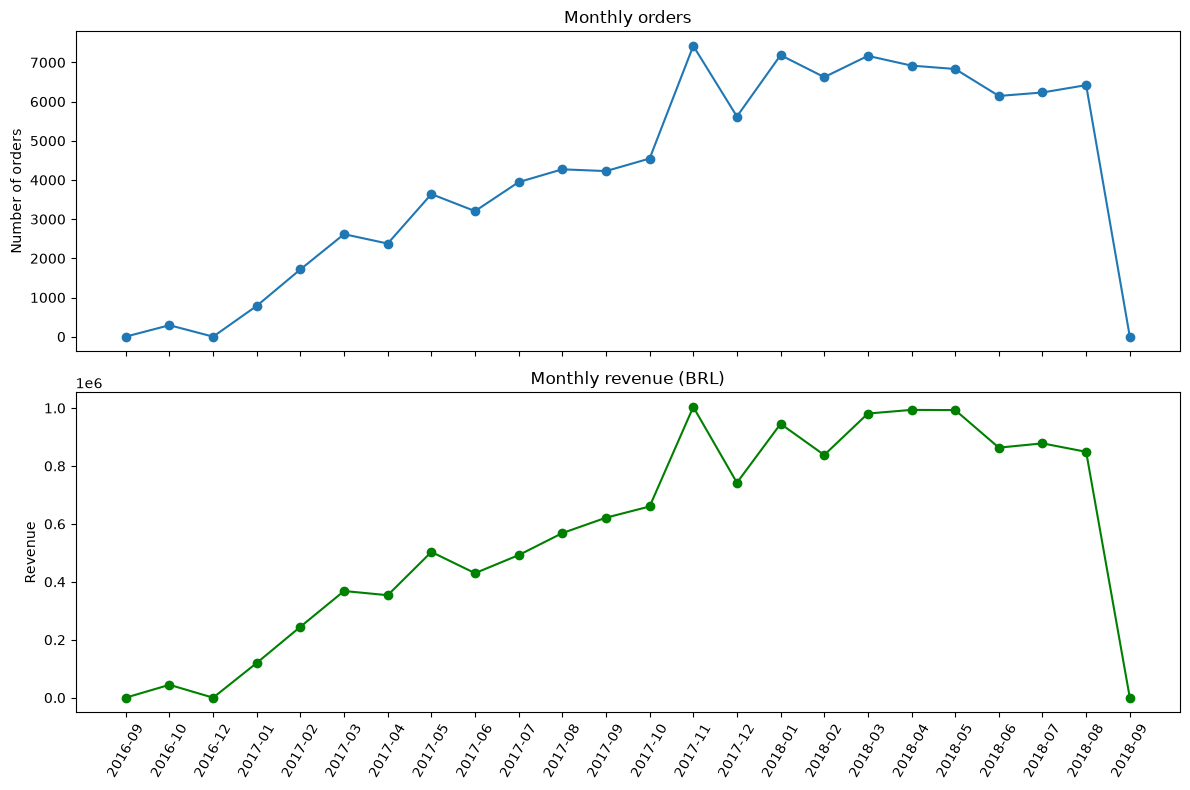

In [22]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

ax[0].plot(monthly["order_month"], monthly["orders"], marker="o")
ax[0].set_title("Monthly orders")
ax[0].set_ylabel("Number of orders")

ax[1].plot(monthly["order_month"], monthly["revenue"], marker="o", color="green")
ax[1].set_title("Monthly revenue (BRL)")
ax[1].set_ylabel("Revenue")

plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

In [23]:
monthly_clean = monthly[(monthly["order_month"] >= "2017-01") &
                        (monthly["order_month"] <= "2018-08")]

     The "so what?"
Orders grew about nine-fold from January 2017 (787) to early 2018 (about 7,200 a month), peaked in November 2017 at 7,423 orders (63% above October), then levelled off at roughly 6,000 to 7,000 a month during 2018. Olist should prepare seller and delivery capacity before each November peak, and investigate why growth stalled in 2018, for example by checking how many customers buy a second time.


November spike: orders jumped 63% from October (4,547 to 7,423). That is probably Black Friday (late November). A sudden surge means Olist's sellers, warehouses and carriers must handle far more orders at once. If they aren't ready, deliveries get late and reviews suffer. We'll test whether November 2017 deliveries were slower when we reach delivery performance.
After the spike: December fell back to 5,620, then January was high again. So the November jump was a peak on top of overall growth, not only a one-off.
2018 plateau: after the rapid 2017 growth, orders stopped growing and stayed around 6,000 to 7,000 a month. Management should ask why: are there too few new customers, or too little repeat buying? We'll look at this in the retention analysis.
A caution: we have only one November in the data (November 2016 is missing). So we can say November 2017 was a peak, but we can't prove it repeats every year.

In [24]:
sales = items_full[~items_full["order_status"].isin(["canceled", "unavailable"])]

cat = (sales.groupby("product_category_name_english")
       .agg(revenue=("price", "sum"),
            orders=("order_id", "nunique"))
       .reset_index())

top_rev = cat.sort_values("revenue", ascending=False).head(10)
top_ord = cat.sort_values("orders", ascending=False).head(10)

print(top_rev)
print(top_ord)

   product_category_name_english     revenue  orders
43                 health_beauty  1255695.13    8800
73                 watches_gifts  1198185.21    5604
7                 bed_bath_table  1035964.06    9399
67                sports_leisure   979740.92    7673
15         computers_accessories   904322.02    6654
39               furniture_decor   727465.05    6425
49                    housewares   626825.80    5847
20                    cool_stuff   620770.49    3616
5                           auto   586585.73    3872
42                  garden_tools   481009.94    3505
   product_category_name_english     revenue  orders
7                 bed_bath_table  1035964.06    9399
43                 health_beauty  1255695.13    8800
67                sports_leisure   979740.92    7673
15         computers_accessories   904322.02    6654
39               furniture_decor   727465.05    6425
49                    housewares   626825.80    5847
73                 watches_gifts  1198185.21  

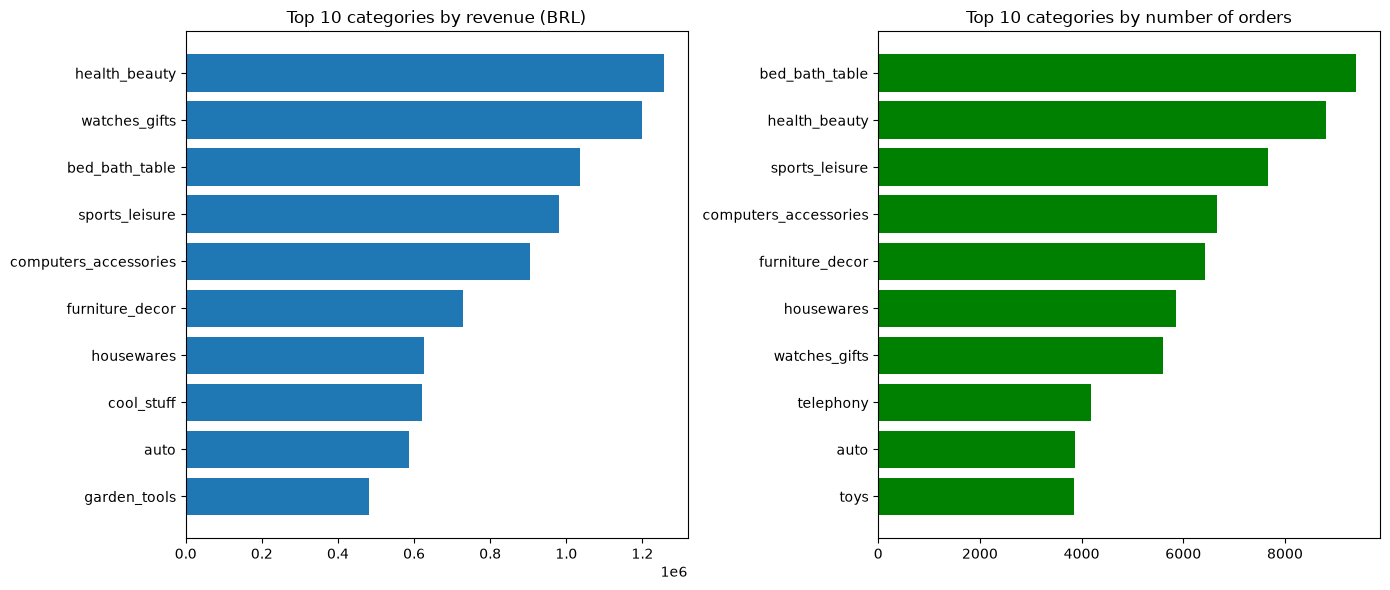

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

ax[0].barh(top_rev["product_category_name_english"], top_rev["revenue"])
ax[0].set_title("Top 10 categories by revenue (BRL)")
ax[0].invert_yaxis()

ax[1].barh(top_ord["product_category_name_english"], top_ord["orders"], color="green")
ax[1].set_title("Top 10 categories by number of orders")
ax[1].invert_yaxis()

plt.tight_layout()
plt.show()


Revenue is spread across many categories: the top 10 of 73 bring in 62.4% of it, and no single category exceeds 9.3%. Watches & gifts earns the second-most revenue from far fewer orders than bed, bath & table, because each order is worth about 214 BRL versus 110. Olist could promote high-value categories like watches & gifts to grow revenue without needing more orders."

Category analysis excludes canceled and unavailable orders. Orders are counted per unique order_id within each category, so an order with items in two categories counts once in each.

In [26]:
cat["revenue_per_order"] = (cat["revenue"] / cat["orders"]).round(1)
cat["share_%"] = (cat["revenue"] / cat["revenue"].sum() * 100).round(1)

top10 = cat.sort_values("revenue", ascending=False).head(10)
print(top10[["product_category_name_english", "revenue", "orders", "revenue_per_order", "share_%"]])
print("Top 10 share of revenue:", top10["share_%"].sum().round(1), "%")
print("Top 5 share of revenue:", top10["share_%"].head(5).sum().round(1), "%")

   product_category_name_english     revenue  orders  revenue_per_order  \
43                 health_beauty  1255695.13    8800              142.7   
73                 watches_gifts  1198185.21    5604              213.8   
7                 bed_bath_table  1035964.06    9399              110.2   
67                sports_leisure   979740.92    7673              127.7   
15         computers_accessories   904322.02    6654              135.9   
39               furniture_decor   727465.05    6425              113.2   
49                    housewares   626825.80    5847              107.2   
20                    cool_stuff   620770.49    3616              171.7   
5                           auto   586585.73    3872              151.5   
42                  garden_tools   481009.94    3505              137.2   

    share_%  
43      9.3  
73      8.9  
7       7.7  
67      7.3  
15      6.7  
39      5.4  
49      4.6  
20      4.6  
5       4.3  
42      3.6  
Top 10 share of reve

In [27]:
state = (valid.groupby("customer_state")
         .agg(orders=("order_id", "count"), revenue=("items_value", "sum"))
         .reset_index()
         .sort_values("revenue", ascending=False))
state["share_%"] = (state["revenue"] / state["revenue"].sum() * 100).round(1)
print(state.head(10))

city = (valid.groupby("customer_city")
        .agg(orders=("order_id", "count"), revenue=("items_value", "sum"))
        .reset_index()
        .sort_values("revenue", ascending=False))
print(city.head(10))

   customer_state  orders     revenue  share_%
25             SP   41127  5163867.22     38.3
18             RJ   12698  1811623.42     13.4
10             MG   11496  1573508.20     11.7
22             RS    5417   742559.78      5.5
17             PR    4983   676883.06      5.0
23             SC    3600   518578.28      3.8
4              BA    3344   507108.83      3.8
6              DF    2121   300886.45      2.2
8              GO    1998   287870.46      2.1
7              ES    2018   273532.13      2.0
       customer_city  orders     revenue
3587       sao paulo   15291  1897019.80
3146  rio de janeiro    6801   986528.05
452   belo horizonte    2737   350760.93
557         brasilia    2112   300202.76
1141        curitiba    1502   208008.66
705         campinas    1422   186925.85
2955    porto alegre    1370   186788.31
3238        salvador    1234   180735.72
1526       guarulhos    1167   142578.38
2455         niteroi     842   117487.43


   customer_state  orders     revenue  share_%
25             SP   41127  5163867.22     38.3
18             RJ   12698  1811623.42     13.4
10             MG   11496  1573508.20     11.7
22             RS    5417   742559.78      5.5
17             PR    4983   676883.06      5.0
23             SC    3600   518578.28      3.8
4              BA    3344   507108.83      3.8
6              DF    2121   300886.45      2.2
8              GO    1998   287870.46      2.1
7              ES    2018   273532.13      2.0
       customer_city  orders     revenue  share_%
3587       sao paulo   15291  1897019.80     14.1
3146  rio de janeiro    6801   986528.05      7.3
452   belo horizonte    2737   350760.93      2.6
557         brasilia    2112   300202.76      2.2
1141        curitiba    1502   208008.66      1.5
705         campinas    1422   186925.85      1.4
2955    porto alegre    1370   186788.31      1.4
3238        salvador    1234   180735.72      1.3
1526       guarulhos    1167   14

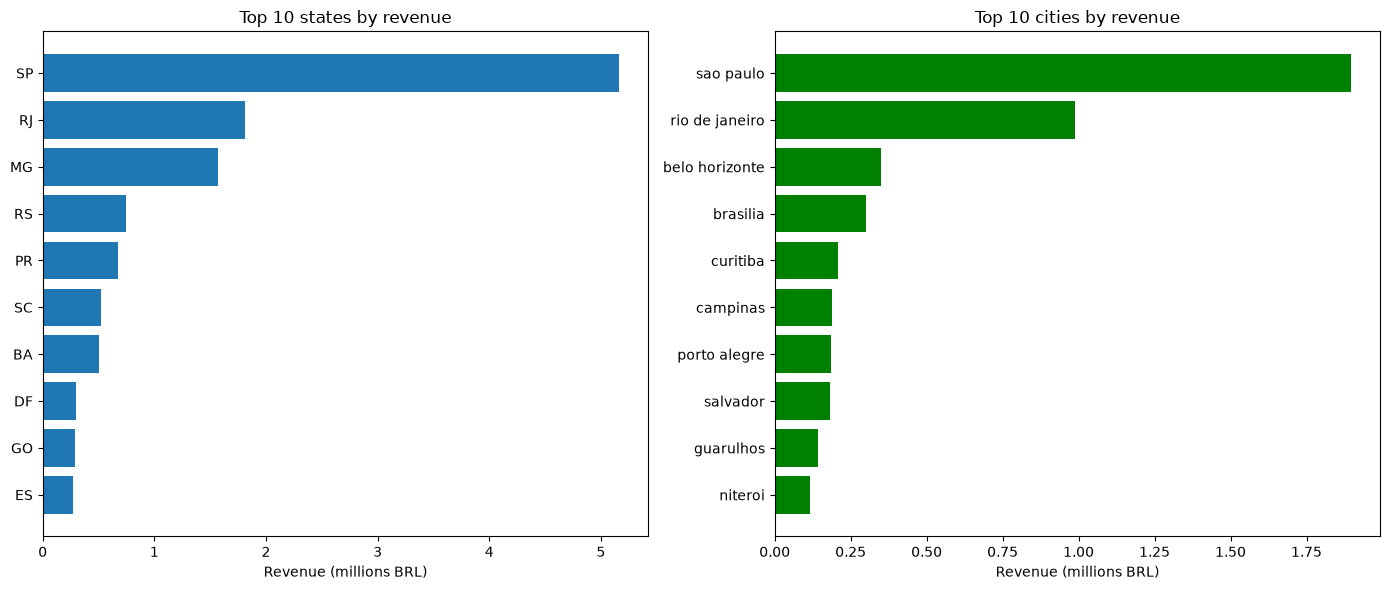

In [28]:
import matplotlib.pyplot as plt

# State table
state = (valid.groupby("customer_state")
         .agg(orders=("order_id", "count"), revenue=("items_value", "sum"))
         .reset_index()
         .sort_values("revenue", ascending=False))
state["share_%"] = (state["revenue"] / state["revenue"].sum() * 100).round(1)

# City table
city = (valid.groupby("customer_city")
        .agg(orders=("order_id", "count"), revenue=("items_value", "sum"))
        .reset_index()
        .sort_values("revenue", ascending=False))
city["share_%"] = (city["revenue"] / city["revenue"].sum() * 100).round(1)

top_state = state.head(10)
top_city = city.head(10)

print(top_state)
print(top_city)

# Charts
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

ax[0].barh(top_state["customer_state"], top_state["revenue"] / 1_000_000)
ax[0].set_title("Top 10 states by revenue")
ax[0].set_xlabel("Revenue (millions BRL)")
ax[0].invert_yaxis()

ax[1].barh(top_city["customer_city"], top_city["revenue"] / 1_000_000, color="green")
ax[1].set_title("Top 10 cities by revenue")
ax[1].set_xlabel("Revenue (millions BRL)")
ax[1].invert_yaxis()

plt.tight_layout()
plt.show()

Sao Paulo state accounts for 38.3% of revenue, almost three times Rio de Janeiro (13.4%), and the top three states account for 63.4%. Olist depends heavily on the Southeast, so a problem there (logistics, a competitor, a slowdown) would hit the business hard. Customers in distant states are a small share today, and if their deliveries are slower, that may be one reason. We will test this in the delivery analysis."
SP state generates 38.3% of revenue, and São Paulo city alone generates 14.1%. Olist depends heavily on one region. We will test later whether customers in distant states receive slower deliveries.

              payments  avg_value  median_value  share_%
payment_type                                            
credit_card      75905      162.7         106.9     74.0
boleto           19539      144.7          93.8     19.0
voucher           5613       62.3          39.0      5.5
debit_card        1516      140.1          89.3      1.5


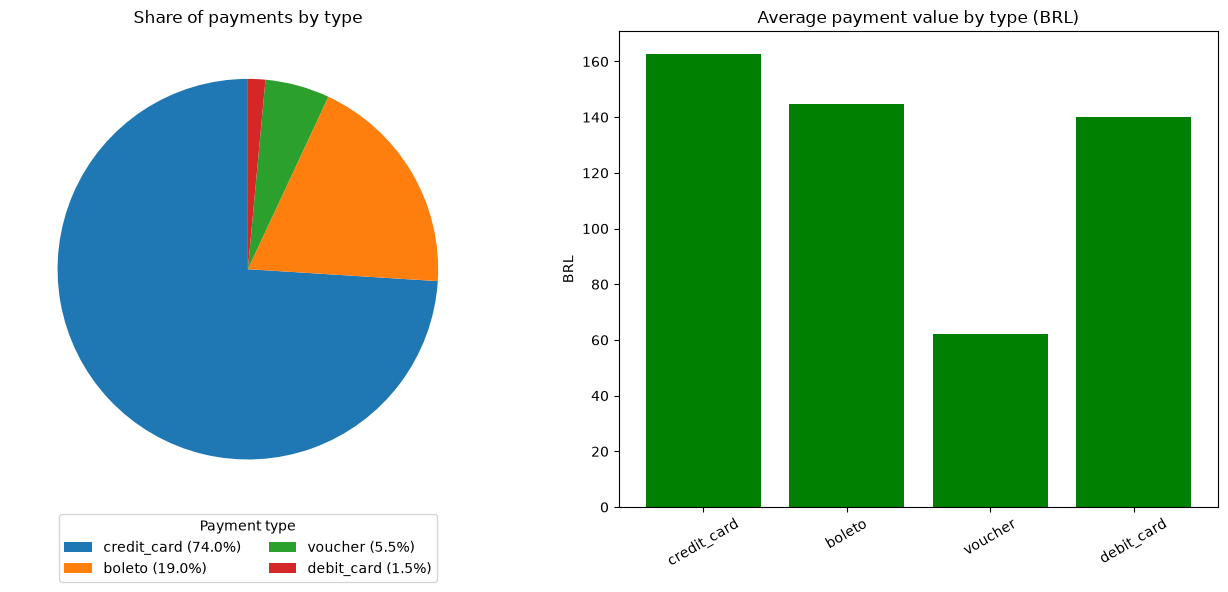

In [29]:
import matplotlib.pyplot as plt

# Rebuild the payment table (valid orders only)
pay = payments[payments["order_id"].isin(valid["order_id"])]

pay_summary = (pay.groupby("payment_type")
               .agg(payments=("order_id", "count"),
                    avg_value=("payment_value", "mean"),
                    median_value=("payment_value", "median"))
               .round(1)
               .sort_values("payments", ascending=False))
pay_summary["share_%"] = (pay_summary["payments"] / pay_summary["payments"].sum() * 100).round(1)
print(pay_summary)

# Charts
fig, ax = plt.subplots(1, 2, figsize=(13, 6))

# Left: pie chart with the names and percentages in a legend below it
labels = [f"{t} ({s}%)" for t, s in zip(pay_summary.index, pay_summary["share_%"])]
wedges, texts = ax[0].pie(pay_summary["payments"], startangle=90)
ax[0].legend(wedges, labels, title="Payment type",
             loc="upper center", bbox_to_anchor=(0.5, 0), ncol=2)
ax[0].set_title("Share of payments by type")

# Right: average payment value by type
ax[1].bar(pay_summary.index, pay_summary["avg_value"], color="green")
ax[1].set_title("Average payment value by type (BRL)")
ax[1].set_ylabel("BRL")
ax[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

Credit card is used for 74% of payments and boleto for 19%, so Olist relies on these two methods for 93% of its payments. Credit card payments are the largest (162.7 BRL on average), while voucher payments are small (62.3 BRL), probably because they are used alongside another method. Olist should keep boleto available to serve customers without credit cards, and make sure the credit card checkout is fast and reliable, since it handles most of the money.

Payment analysis counts payment rows for valid orders; orders with multiple payment methods are counted once per method."

Mean AOV:   137.4
Median AOV: 86.9
count    98199.0
mean       137.4
std        209.3
min          0.8
25%         45.9
50%         86.9
75%        149.9
95%        399.8
99%        995.0
max      13440.0
Name: items_value, dtype: float64


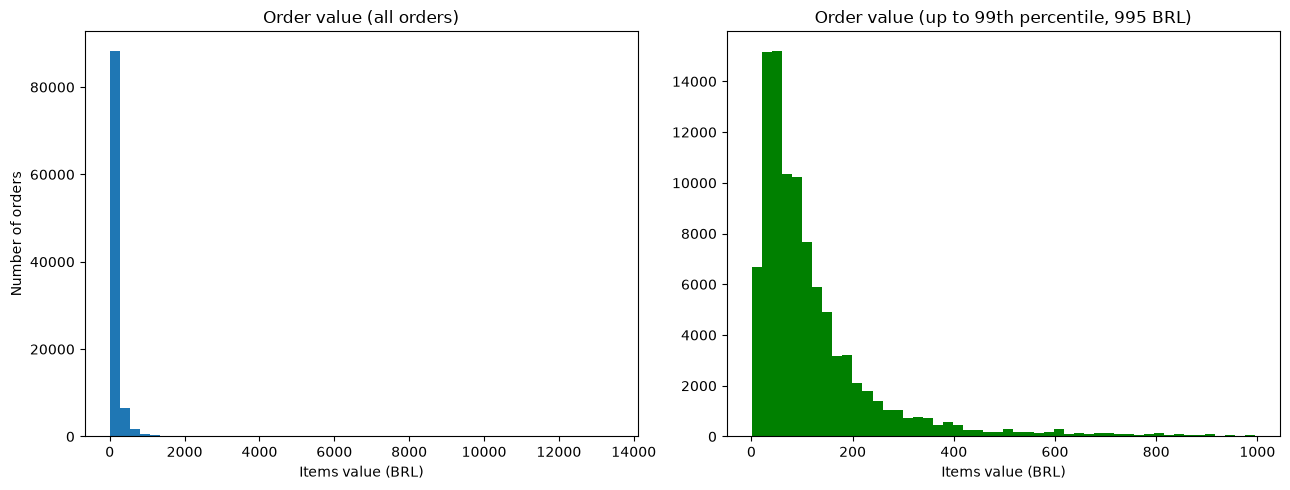

In [30]:
# Question 5

aov = valid["items_value"].dropna()

print("Mean AOV:  ", round(aov.mean(), 1))
print("Median AOV:", round(aov.median(), 1))
print(aov.describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).round(1))

cap = aov.quantile(0.99)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

ax[0].hist(aov, bins=50)
ax[0].set_title("Order value (all orders)")
ax[0].set_xlabel("Items value (BRL)")
ax[0].set_ylabel("Number of orders")

ax[1].hist(aov[aov <= cap], bins=50, color="green")
ax[1].set_title(f"Order value (up to 99th percentile, {cap:,.0f} BRL)")
ax[1].set_xlabel("Items value (BRL)")

plt.tight_layout()
plt.show()

Median delivery days: 10.2
Mean delivery days:   12.6
Late %: 8.1
                orders  median_days  late_pct
customer_state                               
AM                 145         25.9       4.1
AL                 397         22.3      23.9
PA                 946         21.1      12.4
MA                 717         19.2      19.7
PB                 517         18.2      11.0
CE                1279         18.2      15.3
SE                 335         18.0      15.2
RO                 243         17.6       2.9
BA                3256         16.9      14.0
PI                 476         16.3      16.0
MT                 886         16.1       6.8
RN                 474         16.1      10.8
TO                 274         15.9      12.8
PE                1593         15.7      10.8
GO                1957         13.9       8.2
MS                 701         13.9      11.6
ES                1995         13.6      12.2
RS                5344         13.2       7.1
SC            

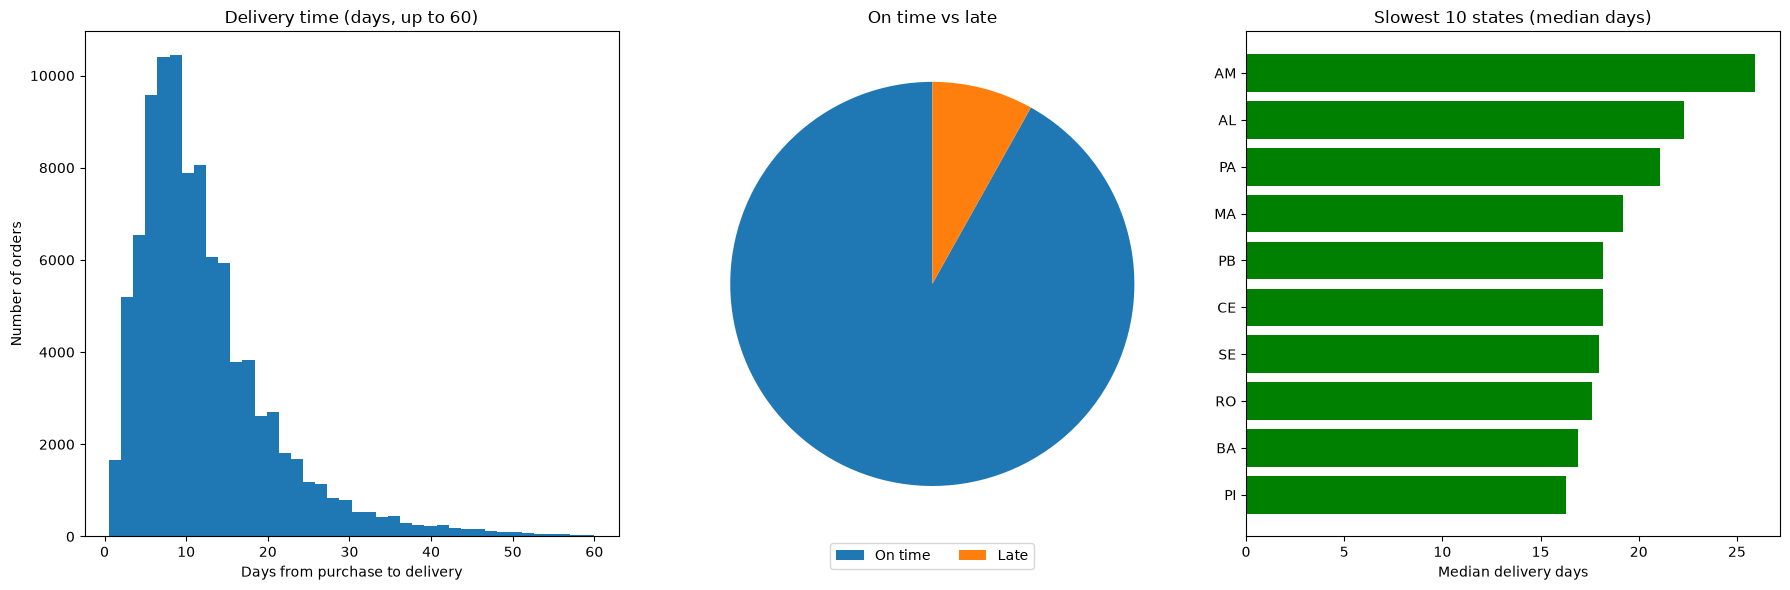

In [31]:
import matplotlib.pyplot as plt

# Overall numbers
print("Median delivery days:", round(delivered["delivery_days"].median(), 1))
print("Mean delivery days:  ", round(delivered["delivery_days"].mean(), 1))
print("Late %:", round(delivered["is_late"].mean() * 100, 1))

# By state (only states with at least 100 orders)
state_del = (delivered.groupby("customer_state")
             .agg(orders=("order_id", "count"),
                  median_days=("delivery_days", "median"),
                  late_pct=("is_late", lambda x: x.mean() * 100))
             .round(1))
state_del = state_del[state_del["orders"] >= 100].sort_values("median_days", ascending=False)
print(state_del)

# Charts
fig, ax = plt.subplots(1, 3, figsize=(18, 6))

# 1. Histogram of delivery days (capped at 60 days)
d = delivered["delivery_days"]
ax[0].hist(d[d <= 60], bins=40)
ax[0].set_title("Delivery time (days, up to 60)")
ax[0].set_xlabel("Days from purchase to delivery")
ax[0].set_ylabel("Number of orders")

# 2. On time vs late
late_counts = delivered["is_late"].value_counts().sort_index()
wedges, texts = ax[1].pie(late_counts, startangle=90)
ax[1].legend(wedges, ["On time", "Late"], loc="upper center",
             bbox_to_anchor=(0.5, 0), ncol=2)
ax[1].set_title("On time vs late")

# 3. Slowest 10 states by median delivery days
slow = state_del.head(10)
ax[2].barh(slow.index, slow["median_days"], color="green")
ax[2].set_title("Slowest 10 states (median days)")
ax[2].set_xlabel("Median delivery days")
ax[2].invert_yaxis()

plt.tight_layout()
plt.show()

Notes:

The state table keeps only states with at least 100 orders, because a median from a few orders isn't reliable. Add that to your log.
The histogram stops at 60 days, so the few extreme cases (up to about 210 days) don't squash the chart. Say so in your log, as you did for the order-value histogram.
Earlier I suggested that states far from SP wait longer. That's still only a hypothesis, and this table will show whether it holds.

In [32]:
late_by_state = (delivered.groupby("customer_state")
                 .agg(orders=("order_id", "count"),
                      late_orders=("is_late", "sum"))
                 .sort_values("late_orders", ascending=False))
late_by_state["share_of_all_late_%"] = (late_by_state["late_orders"] /
                                        late_by_state["late_orders"].sum() * 100).round(1)
print(late_by_state.head(8))

                orders  late_orders  share_of_all_late_%
customer_state                                          
SP               40494       2387.0                 30.5
RJ               12350       1664.0                 21.3
MG               11354        637.0                  8.1
BA                3256        457.0                  5.8
RS                5344        382.0                  4.9
SC                3546        346.0                  4.4
PR                4923        246.0                  3.1
ES                1995        244.0                  3.1


Typical delivery takes 10.2 days and 8.1% of orders arrive late. Delivery is fastest in SP (7.2 days) and slowest in the North and Northeast (16 to 26 days). Alagoas (23.9%) and Maranhão (19.7%) have the highest late rates, and Rio de Janeiro is a key problem because it is a high-revenue state with 13.5% late orders. Olist should work with carriers in AL, MA and RJ, and review whether its delivery estimates in these states are realistic."

Orders with a review: 95824
Average score: 4.16
review_score
1.0     9.8
2.0     3.0
3.0     8.3
4.0    19.7
5.0    59.2
Name: proportion, dtype: float64
                       orders  avg_score  pct_1star
delivery_group                                     
On time                 88163       4.29       6.59
1-5 days late            3568       3.46      21.97
More than 5 days late    4093       1.78      67.33


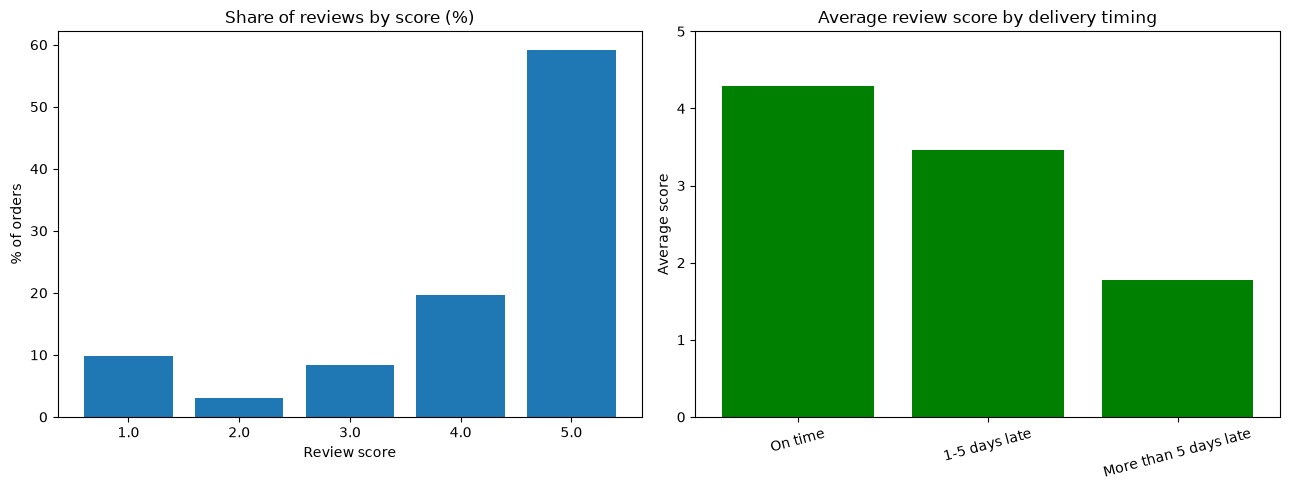

In [33]:
import pandas as pd
import matplotlib.pyplot as plt

rev = delivered.dropna(subset=["review_score"]).copy()
print("Orders with a review:", len(rev))
print("Average score:", round(rev["review_score"].mean(), 2))

# Share of each score
dist = rev["review_score"].value_counts(normalize=True).sort_index().mul(100).round(1)
print(dist)

# On time vs late groups
rev["delivery_group"] = pd.cut(rev["delay_days"],
                               bins=[-1000, 0, 5, 1000],
                               labels=["On time", "1-5 days late", "More than 5 days late"])

group = (rev.groupby("delivery_group", observed=True)
         .agg(orders=("order_id", "count"),
              avg_score=("review_score", "mean"),
              pct_1star=("review_score", lambda x: (x == 1).mean() * 100))
         .round(2))
print(group)

# Charts
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

ax[0].bar(dist.index.astype(str), dist.values)
ax[0].set_title("Share of reviews by score (%)")
ax[0].set_xlabel("Review score")
ax[0].set_ylabel("% of orders")

ax[1].bar(group.index.astype(str), group["avg_score"], color="green")
ax[1].set_title("Average review score by delivery timing")
ax[1].set_ylabel("Average score")
ax[1].set_ylim(0, 5)
ax[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.savefig("q7_satisfaction.png", dpi=150, bbox_inches="tight")
plt.show()

                       What the numbers show
Both hypotheses are supported. The score distribution is lopsided: 59.2% of reviews are 5 stars, and 1 star (9.8%) is more common than 2 stars (3.0%), the bump at 1 star" I predicted. The average score is 4.16.
Late delivery hurts reviews a lot, and it gets worse the later the order is. A delay of up to 5 days drops the score by 0.83 stars, and more than 5 days drops it by 2.51 stars.
Two out of three orders that arrive more than 5 days late get a 1-star review, against about 1 in 15 for on-time orders. That is roughly 10 times the rate.
Late orders cause a disproportionate amount of unhappiness. They are only about 8% of the reviewed orders, but by my rough calculation they produce about 38% of all 1-star reviews. If late orders scored like on-time ones, the overall average would rise by roughly 0.14 stars (4.16 to about 4.30). These are my estimates, so verify them with the code below.
Late delivery is associated with lower scores, not that it causes them. Late orders may also have other problems, such as damaged or wrong items. Using "associated" is the honest wording, and interviewers notice it.

"So what?" for Question 7

"The average review score is 4.16, and 59% of reviews are 5 stars. But orders more than 5 days late average only 1.78 stars versus 4.29 for on-time orders, a gap of 2.51 stars, and 67% of them get a 1-star review. Late orders are only about 8% of reviews yet account for a large share of the 1-star reviews. Reducing late deliveries, especially in AL, MA and RJ, is the clearest way to improve customer satisfaction."

Unique customers: 94990
orders
1     92102
2      2652
3       188
4        29
5         9
6         5
7         3
9         1
16        1
Name: count, dtype: int64
Repeat customers (2+ orders): 3.0 %
months_since     1     2     3     4     5     6
cohort                                          
2017-01       0.40  0.27  0.13  0.40  0.13  0.40
2017-02       0.24  0.30  0.12  0.41  0.12  0.24
2017-03       0.51  0.35  0.39  0.35  0.16  0.16
2017-04       0.60  0.22  0.17  0.30  0.26  0.34
2017-05       0.48  0.48  0.40  0.31  0.34  0.42
2017-06       0.45  0.35  0.39  0.26  0.39  0.35
2017-07       0.52  0.34  0.24  0.29  0.21  0.31
2017-08       0.68  0.34  0.27  0.36  0.53  0.29
2017-09       0.69  0.54  0.29  0.44  0.22  0.22
2017-10       0.71  0.25  0.09  0.23  0.20  0.20
2017-11       0.56  0.39  0.17  0.19  0.18  0.11
2017-12       0.22  0.28  0.35  0.26  0.20  0.17
2018-01       0.33  0.36  0.29  0.29  0.16  0.17
2018-02       0.36  0.39  0.30  0.27  0.22  0.20


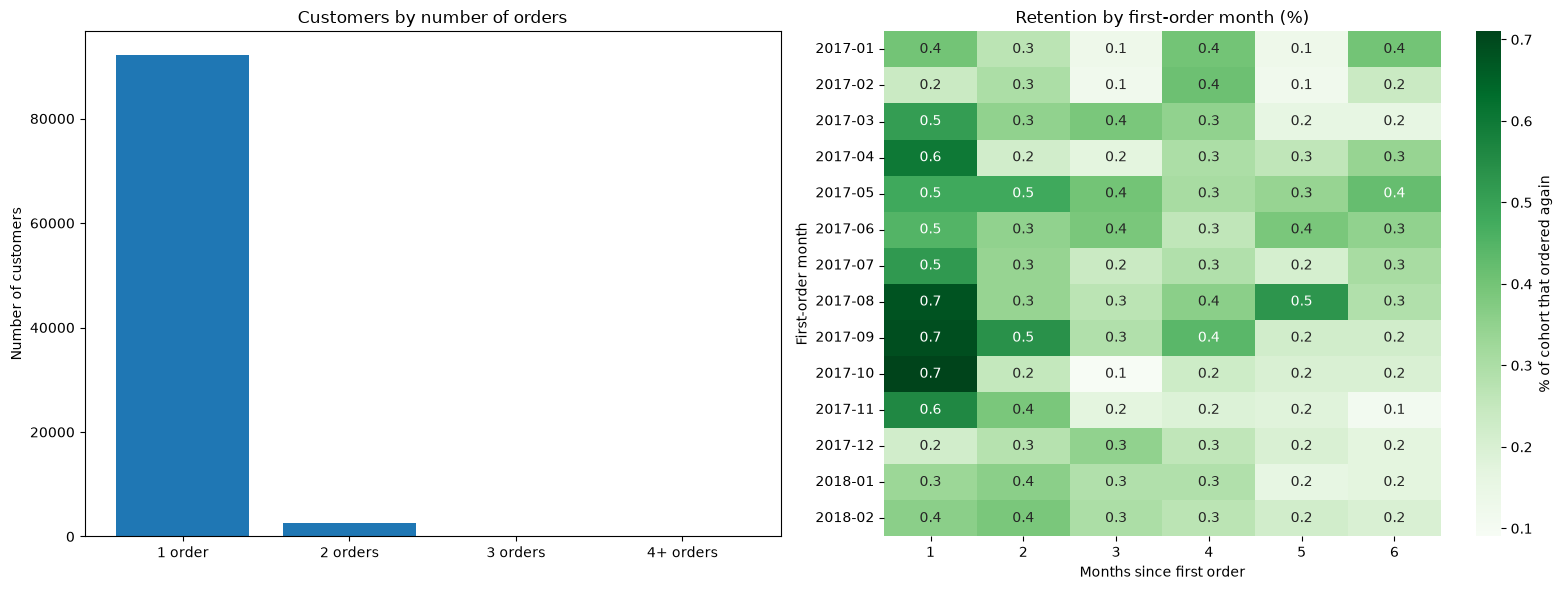

In [34]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Orders per real customer
cust = (valid.groupby("customer_unique_id")
        .agg(orders=("order_id", "count"))
        .reset_index())

print("Unique customers:", len(cust))
print(cust["orders"].value_counts().sort_index())
print("Repeat customers (2+ orders):", round((cust["orders"] > 1).mean() * 100, 1), "%")

# 2. Cohort table: month of first order vs months since
v = valid[["customer_unique_id", "order_purchase_timestamp"]].copy()
v["order_month"] = v["order_purchase_timestamp"].dt.to_period("M")
v["cohort"] = v.groupby("customer_unique_id")["order_month"].transform("min")
v["months_since"] = ((v["order_month"].dt.year - v["cohort"].dt.year) * 12 +
                     (v["order_month"].dt.month - v["cohort"].dt.month))

# Keep cohorts that have at least 6 months of follow-up
v = v[(v["cohort"] >= pd.Period("2017-01", "M")) &
      (v["cohort"] <= pd.Period("2018-02", "M"))]

cohort_counts = (v.groupby(["cohort", "months_since"])["customer_unique_id"]
                 .nunique().unstack(fill_value=0))
retention = cohort_counts.div(cohort_counts[0], axis=0) * 100
retention = retention[[1, 2, 3, 4, 5, 6]].round(2)
print(retention)

# 3. Charts
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

vc = cust["orders"].clip(upper=4).value_counts().sort_index()
ax[0].bar(["1 order", "2 orders", "3 orders", "4+ orders"], vc.values)
ax[0].set_title("Customers by number of orders")
ax[0].set_ylabel("Number of customers")

sns.heatmap(retention, annot=True, fmt=".1f", cmap="Greens", ax=ax[1],
            cbar_kws={"label": "% of cohort that ordered again"})
ax[1].set_title("Retention by first-order month (%)")
ax[1].set_xlabel("Months since first order")
ax[1].set_ylabel("First-order month")

plt.tight_layout()
plt.savefig("q8_retention.png", dpi=150, bbox_inches="tight")
plt.show()

What the numbers show

1. Almost everyone orders once.

Of 94,990 unique customers, 92,102 (97.0%) ordered once and only 2,888 (3.0%) ordered more than once.
2,652 ordered twice, and just 188 ordered three times. The bar chart shows this: the "3 orders" and "4+ orders" bars are too small to see.
One customer placed 16 orders. That is probably a business buyer or a reseller, so it's worth a note, but not worth chasing.

2. Read the heatmap numbers as percentages. The cells are already percentages, so 0.4 means 0.4%, not 40%. Each cell shows the share of a cohort that ordered again in that specific month:

Month 1 after the first order is 0.2% to 0.7%.
By months 3 to 6 it falls to 0.1% to 0.4%.
Adding up the six months gives roughly 1.4% to 2.5% of each cohort coming back. That's approximate, because a customer who orders in two different months is counted twice.

3. A pattern worth noting. The August to October 2017 cohorts have the strongest return in month 1 (0.68%, 0.69% and 0.71%). December 2017 is the weakest (0.22%). I can't tell you why from this data, so treat it as a question to investigate, not a finding.

4. Be careful with the early cohorts. January and February 2017 were small cohorts (787 and 1,718 orders in the monthly table), and 0.4% of a few hundred customers is only a handful of people. Their numbers jump around, so don't read much into them.

                  Limits 
We can only see 6 months of follow-up, so customers who return after a year are not counted.
A customer who creates a new account can look like a new person. The data's customer_unique_id handles most of this, but not perfectly.
Olist may simply sell things people buy once (furniture, electronics), so low repeat rates aren't necessarily a failure.

                      customers    revenue  avg_recency_days  avg_spend  \
segment                                                                   
New high-value            14731  3946893.4              96.9      267.9   
At risk (high value)      14003  3891587.3             400.6      277.9   
Needs attention           18386  2399228.9             225.3      130.5   
Lost                      22959  1280829.0             400.9       55.8   
New customers             22023  1225365.7              94.6       55.6   
Repeat (not recent)        1646   415959.5             326.5      252.7   
Champions                  1242   334537.0              94.0      269.4   

                      customers_%  revenue_%  
segment                                       
New high-value               15.5       29.2  
At risk (high value)         14.7       28.8  
Needs attention              19.4       17.8  
Lost                         24.2        9.5  
New customers                23.2        9

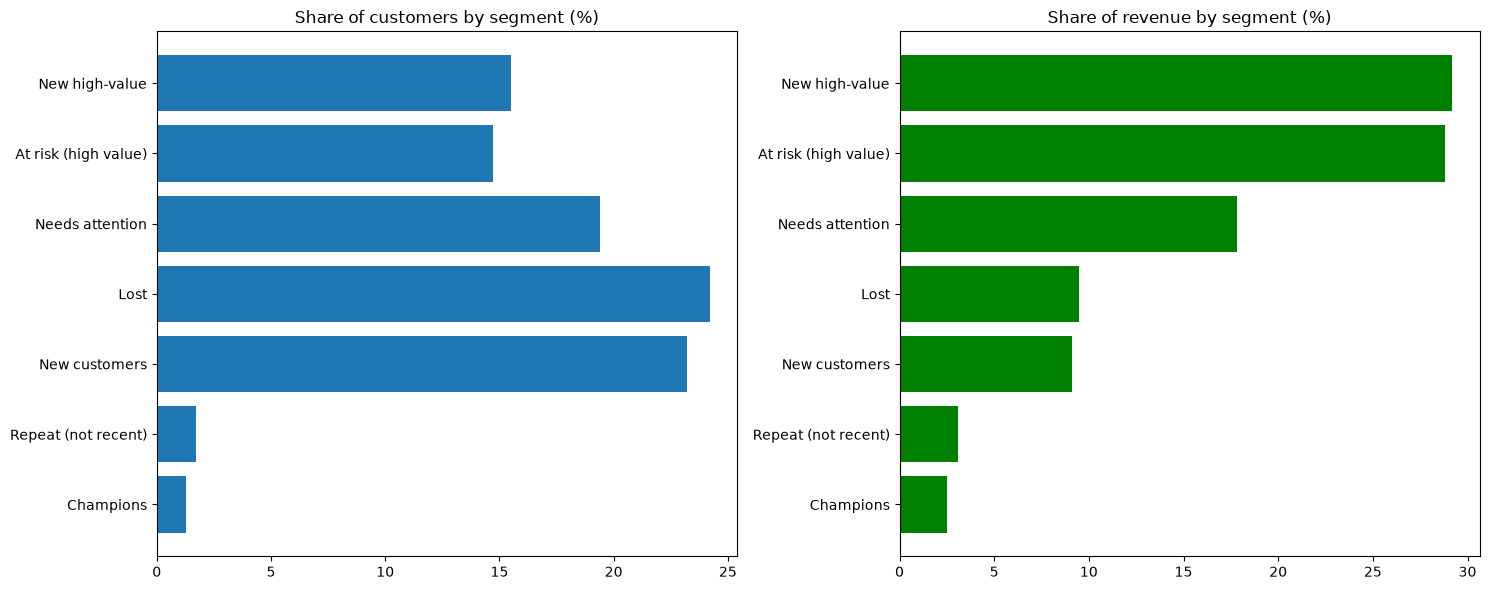

In [35]:
# Question 9
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. One row per real customer
ref_date = valid["order_purchase_timestamp"].max() + pd.Timedelta(days=1)

rfm = (valid.groupby("customer_unique_id")
       .agg(last_order=("order_purchase_timestamp", "max"),
            frequency=("order_id", "nunique"),
            monetary=("items_value", "sum"))
       .reset_index())
rfm["recency"] = (ref_date - rfm["last_order"]).dt.days

# 2. Scores from 1 to 5 (5 = best)
rfm["R"] = pd.qcut(rfm["recency"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["M"] = pd.qcut(rfm["monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)

# 3. Segment rules
conditions = [
    (rfm["frequency"] >= 2) & (rfm["R"] >= 4),
    (rfm["frequency"] >= 2),
    (rfm["R"] >= 4) & (rfm["M"] >= 4),
    (rfm["R"] >= 4),
    (rfm["R"] <= 2) & (rfm["M"] >= 4),
    (rfm["R"] <= 2),
]
names = ["Champions", "Repeat (not recent)", "New high-value", "New customers",
         "At risk (high value)", "Lost"]
rfm["segment"] = np.select(conditions, names, default="Needs attention")

# 4. Summary table
seg = (rfm.groupby("segment")
       .agg(customers=("customer_unique_id", "count"),
            revenue=("monetary", "sum"),
            avg_recency_days=("recency", "mean"),
            avg_spend=("monetary", "mean"))
       .round(1))
seg["customers_%"] = (seg["customers"] / seg["customers"].sum() * 100).round(1)
seg["revenue_%"] = (seg["revenue"] / seg["revenue"].sum() * 100).round(1)
seg = seg.sort_values("revenue", ascending=False)
print(seg)

# 5. Charts (bars, because there are too many segments for a readable pie)
fig, ax = plt.subplots(1, 2, figsize=(15, 6))

ax[0].barh(seg.index, seg["customers_%"])
ax[0].set_title("Share of customers by segment (%)")
ax[0].invert_yaxis()

ax[1].barh(seg.index, seg["revenue_%"], color="green")
ax[1].set_title("Share of revenue by segment (%)")
ax[1].invert_yaxis()

plt.tight_layout()
plt.savefig("q9_rfm_segments.png", dpi=150, bbox_inches="tight")
plt.show()

Sellers with sales: 3053
                             seller_id seller_state    revenue  orders  \
849   4869f7a5dfa277a7dca6462dcf3b52b2           SP  229237.63    1131   
1000  53243585a1d6dc2643021fd1853d8905           BA  222776.05     358   
873   4a3ca9315b744ce9f8e9374361493884           SP  200326.12    1804   
2984  fa1c13f2614d7b5c4749cbc52fecda94           SP  192842.13     584   
1515  7c67e1448b00f6e969d365cea6b010ab           SP  187923.89     982   
1540  7e93a43ef30c4f03f38b393420bc753a           SP  172583.88     332   
2611  da8622b14eb17ae2831f4ac5b9dab84a           SP  160236.57    1314   
1485  7a67c85e85bb2ce8582c35f2203ad736           SP  141715.54    1159   
191   1025f0e2d44d7041d6cf58b6550e0bfa           SP  138968.55     915   
1799  955fee9216a65b617aa5c0531780ce60           SP  135159.70    1286   

      avg_score  median_days  late_pct  revenue_%  
849        4.14        12.11     11.57       1.70  
1000       4.13        11.53      4.31       1.65  
873 

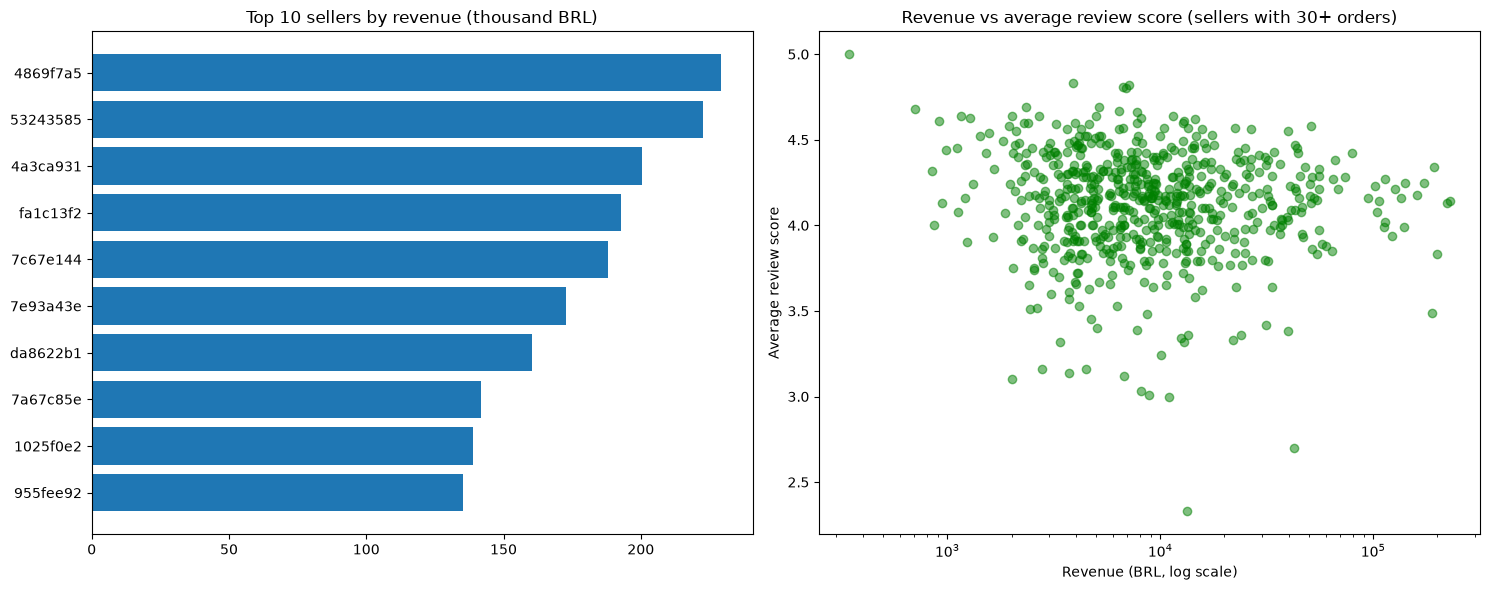

In [36]:
# Question 10
import pandas as pd
import matplotlib.pyplot as plt

sales = items_full[~items_full["order_status"].isin(["canceled", "unavailable"])]

# 1. Revenue per seller
rev = (sales.groupby("seller_id")
       .agg(revenue=("price", "sum"))
       .reset_index())

# 2. One row per seller-order, with review and delivery info
so = (sales.drop_duplicates(subset=["order_id", "seller_id"])
      [["order_id", "seller_id", "review_score"]]
      .merge(delivered[["order_id", "delivery_days", "is_late"]], on="order_id", how="left"))

perf = (so.groupby("seller_id")
        .agg(orders=("order_id", "nunique"),
             avg_score=("review_score", "mean"),
             median_days=("delivery_days", "median"),
             late_pct=("is_late", lambda x: x.mean() * 100))
        .reset_index())

seller_df = (rev.merge(perf, on="seller_id")
             .merge(sellers[["seller_id", "seller_state"]], on="seller_id", how="left")
             .round(2))
seller_df["revenue_%"] = (seller_df["revenue"] / seller_df["revenue"].sum() * 100).round(2)

print("Sellers with sales:", len(seller_df))

# 3. Top 10 sellers and their concentration
top10 = seller_df.sort_values("revenue", ascending=False).head(10)
print(top10[["seller_id", "seller_state", "revenue", "orders", "avg_score",
             "median_days", "late_pct", "revenue_%"]])
print("Top 10 sellers share of revenue:", top10["revenue_%"].sum().round(1), "%")

# 4. Where are the sellers? (share of revenue by seller state)
seller_state = (seller_df.groupby("seller_state")
                .agg(sellers=("seller_id", "count"), revenue=("revenue", "sum")))
seller_state["revenue_%"] = (seller_state["revenue"] / seller_state["revenue"].sum() * 100).round(1)
print(seller_state.sort_values("revenue", ascending=False).head(6))

# 5. Do big sellers also perform well? (sellers with at least 30 orders only)
big = seller_df[seller_df["orders"] >= 30]
print("Sellers with 30+ orders:", len(big))
print(big[["revenue", "avg_score", "median_days", "late_pct"]].corr(method="spearman").round(2))

# 6. Charts
fig, ax = plt.subplots(1, 2, figsize=(15, 6))

ax[0].barh(top10["seller_id"].str[:8], top10["revenue"] / 1000)
ax[0].set_title("Top 10 sellers by revenue (thousand BRL)")
ax[0].invert_yaxis()

ax[1].scatter(big["revenue"], big["avg_score"], alpha=0.5, color="green")
ax[1].set_xscale("log")
ax[1].set_title("Revenue vs average review score (sellers with 30+ orders)")
ax[1].set_xlabel("Revenue (BRL, log scale)")
ax[1].set_ylabel("Average review score")

plt.tight_layout()
plt.savefig("q10_sellers.png", dpi=150, bbox_inches="tight")
plt.show()

In [37]:
# Concentration: how much revenue do the top 10% of sellers bring in?
s = seller_df.sort_values("revenue", ascending=False)
k = int(len(s) * 0.1)
print("Top 10% of sellers:", round(s.head(k)["revenue_%"].sum(), 1), "% of revenue")

# Same-state vs cross-state orders
x = (items_full[~items_full["order_status"].isin(["canceled", "unavailable"])]
     .drop_duplicates(subset=["order_id", "seller_id"])
     [["order_id", "seller_state", "customer_state"]]
     .merge(delivered[["order_id", "delivery_days", "is_late", "review_score"]], on="order_id"))
x["same_state"] = x["seller_state"] == x["customer_state"]

print(x.groupby("same_state")
        .agg(orders=("order_id", "count"),
             median_days=("delivery_days", "median"),
             late_pct=("is_late", lambda v: v.mean() * 100),
             avg_score=("review_score", "mean"))
        .round(2))

Top 10% of sellers: 67.5 % of revenue
            orders  median_days  late_pct  avg_score
same_state                                          
False        62630        12.73      9.16       4.08
True         35181         6.51      5.99       4.25


What the numbers show?

1. Revenue is spread across many sellers. The top 10 of 3,053 sellers bring in only 13.2% of revenue, and the biggest single seller has 1.7%. Olist depends on a long tail of many small sellers, not on a few giants. The top 10 sellers also include a lot of orders (up to 1,804 for one seller), so these are busy businesses.

2. Bigger sellers are not better sellers. The correlation table covers the 634 sellers with 30 or more orders:

Pair	Correlation	Meaning
revenue and avg_score	-0.08	No real relationship
revenue and late_pct	0.08	No real relationship
revenue and median_days	0.17	Weak: bigger sellers are slightly slower
avg_score and late_pct	-0.45	Moderate: sellers with more late orders score lower
avg_score and median_days	-0.40	Moderate: slower sellers score lower

The scatter plot shows the same thing: the dots form a flat cloud, with no upward slope as revenue grows. This repeats your Question 7 finding at the seller level: delivery performance, not size, goes with reviews. The -0.45 is a moderate relationship, not a strong one, and it shows an association, not proof of cause.

3. The top 10 are average, not outstanding. Their average score is about 4.1, close to the platform's 4.16. Individual sellers differ a lot:

Best performers: da8622b1 (4.18 stars, 8.2 days, 7.6% late) and 7e93a43e (4.25 stars, 8.9 days, 5.6% late).
Problem seller: 7c67e144 earns 1.39% of revenue (188k BRL) but has 3.49 stars and a median delivery of 19.8 days, about twice the platform's median. This is a high-revenue seller who damages customer satisfaction, so it's the clearest example for your report.
4a3ca931 has 1,804 orders (the most), but only 3.83 stars and 11% late.
53243585 is the only top-10 seller outside SP (in BA), with just 4.3% late. It earns 223k BRL from only 358 orders, so each order is large (about 620 BRL).

4. Sellers are even more concentrated in SP than customers. SP has 1,822 of 3,053 sellers (60%) and 64.4% of seller revenue, against 38.3% of customer revenue. SP sellers ship to customers all over Brazil. That supports your earlier idea that distance from SP explains slow deliveries in the North and Northeast. It is still a hypothesis, and the check below tests it.

5. A few low-score outliers. At the bottom of the scatter, a few sellers with 30+ orders average below 3 stars (one is around 2.3). They are a risk to the brand.

In [39]:
import os, glob, shutil
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("olist_outputs/data", exist_ok=True)
os.makedirs("olist_outputs/charts", exist_ok=True)

# ---------- 1. Data files ----------
master.to_csv("olist_outputs/data/master_clean.csv", index=False)
items_full.to_csv("olist_outputs/data/items_full.csv", index=False)
rfm.to_csv("olist_outputs/data/rfm_customers.csv", index=False)
seller_df.to_csv("olist_outputs/data/seller_performance.csv", index=False)

# ---------- 2. One Excel file with a sheet per result ----------
ret = retention.copy()
ret.index = ret.index.astype(str)

sheets = {
    "monthly": (monthly_clean, False),
    "categories": (cat.sort_values("revenue", ascending=False), False),
    "states": (state, False),
    "top_cities": (city.head(50), False),
    "payments": (pay_summary, True),
    "delivery_by_state": (state_del, True),
    "satisfaction_groups": (group, True),
    "retention_cohorts": (ret, True),
    "rfm_segments": (seg, True),
    "top_sellers": (top10, False),
    "seller_states": (seller_state, True),
}
with pd.ExcelWriter("olist_outputs/olist_results.xlsx") as writer:
    for name, (df, keep_index) in sheets.items():
        df.to_excel(writer, sheet_name=name, index=keep_index)

# ---------- 3. Charts for questions 1 to 6 ----------
def save(name):
    plt.tight_layout()
    plt.savefig(f"olist_outputs/charts/{name}.png", dpi=150, bbox_inches="tight")
    plt.close()

# Q1 monthly trend
fig, ax = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
ax[0].plot(monthly_clean["order_month"], monthly_clean["orders"], marker="o")
ax[0].set_title("Monthly orders (Jan 2017 to Aug 2018)"); ax[0].set_ylabel("Orders")
ax[1].plot(monthly_clean["order_month"], monthly_clean["revenue"], marker="o", color="green")
ax[1].set_title("Monthly revenue (BRL)"); ax[1].set_ylabel("Revenue")
plt.xticks(rotation=60)
save("q1_monthly_trend")

# Q2 categories
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
ax[0].barh(top_rev["product_category_name_english"], top_rev["revenue"] / 1e6)
ax[0].set_title("Top 10 categories by revenue"); ax[0].set_xlabel("Revenue (millions BRL)"); ax[0].invert_yaxis()
ax[1].barh(top_ord["product_category_name_english"], top_ord["orders"], color="green")
ax[1].set_title("Top 10 categories by orders"); ax[1].invert_yaxis()
save("q2_top_categories")

# Q3 states and cities
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
ax[0].barh(top_state["customer_state"], top_state["revenue"] / 1e6)
ax[0].set_title("Top 10 states by revenue"); ax[0].set_xlabel("Revenue (millions BRL)"); ax[0].invert_yaxis()
ax[1].barh(top_city["customer_city"], top_city["revenue"] / 1e6, color="green")
ax[1].set_title("Top 10 cities by revenue"); ax[1].set_xlabel("Revenue (millions BRL)"); ax[1].invert_yaxis()
save("q3_states_cities")

# Q4 payments
fig, ax = plt.subplots(1, 2, figsize=(13, 6))
labels = [f"{t} ({s}%)" for t, s in zip(pay_summary.index, pay_summary["share_%"])]
wedges, texts = ax[0].pie(pay_summary["payments"], startangle=90)
ax[0].legend(wedges, labels, title="Payment type", loc="upper center", bbox_to_anchor=(0.5, 0), ncol=2)
ax[0].set_title("Share of payments by type")
ax[1].bar(pay_summary.index, pay_summary["avg_value"], color="green")
ax[1].set_title("Average payment value by type (BRL)"); ax[1].set_ylabel("BRL")
ax[1].tick_params(axis="x", rotation=30)
save("q4_payments")

# Q5 order value
aov = valid["items_value"].dropna()
cap = aov.quantile(0.99)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].hist(aov, bins=50); ax[0].set_title("Order value (all orders)")
ax[0].set_xlabel("Items value (BRL)"); ax[0].set_ylabel("Number of orders")
ax[1].hist(aov[aov <= cap], bins=50, color="green")
ax[1].set_title(f"Order value (up to 99th percentile, {cap:,.0f} BRL)"); ax[1].set_xlabel("Items value (BRL)")
save("q5_order_value")

# Q6 delivery
fig, ax = plt.subplots(1, 3, figsize=(18, 6))
d = delivered["delivery_days"]
ax[0].hist(d[d <= 60], bins=40); ax[0].set_title("Delivery time (days, up to 60)")
ax[0].set_xlabel("Days from purchase to delivery"); ax[0].set_ylabel("Number of orders")
late_counts = delivered["is_late"].value_counts().sort_index()
wedges, texts = ax[1].pie(late_counts, startangle=90)
ax[1].legend(wedges, ["On time", "Late"], loc="upper center", bbox_to_anchor=(0.5, 0), ncol=2)
ax[1].set_title("On time vs late")
slow = state_del.head(10)
ax[2].barh(slow.index, slow["median_days"], color="green")
ax[2].set_title("Slowest 10 states (median days)"); ax[2].set_xlabel("Median delivery days"); ax[2].invert_yaxis()
save("q6_delivery")

# ---------- 4. Copy charts saved earlier (Q7 to Q10) ----------
for f in glob.glob("q7_*.png") + glob.glob("q8_*.png") + glob.glob("q9_*.png") + glob.glob("q10_*.png"):
    shutil.copy(f, "olist_outputs/charts/")

# ---------- 5. Zip everything ----------
shutil.make_archive("olist_outputs", "zip", "olist_outputs")

print("Data files:  ", sorted(os.listdir("olist_outputs/data")))
print("Excel file:  ", os.path.exists("olist_outputs/olist_results.xlsx"))
print("Charts saved:", sorted(os.listdir("olist_outputs/charts")))

Data files:   ['items_full.csv', 'master_clean.csv', 'rfm_customers.csv', 'seller_performance.csv']
Excel file:   True
Charts saved: ['q10_sellers.png', 'q1_monthly_trend.png', 'q2_top_categories.png', 'q3_states_cities.png', 'q4_payments.png', 'q5_order_value.png', 'q6_delivery.png', 'q7_satisfaction.png', 'q8_retention.png', 'q9_rfm_segments.png']


                                                RECOMENDATIONS
1. Reduce late deliveries, starting in Rio de Janeiro, Alagoas and Maranhao

Finding: late delivery is the clearest driver of unhappy customers.
Evidence: 8.1% of orders arrive late. Orders more than 5 days late average 1.78 stars versus 4.29 on time, and 67.3% of them get a 1-star review. AL (23.9% late) and MA (19.7%) have the worst late rates. RJ, the second-biggest state by revenue (13.4%), has 13.5% late, about 1,670 late orders.
Action: review carrier performance in RJ, AL and MA, and set late-delivery targets for them.
Benefit: fewer 1-star reviews and a higher average score (currently 4.16).

2. Make delivery estimates more realistic

Finding: estimates are very cautious on average, yet some states still miss them.
Evidence: orders arrive about 11 days before the estimate on average, but AL and MA are late on 20% or more of orders.
Action: use state-specific estimates, so slow regions get realistic dates.
Benefit: fewer broken promises. Note the trade-off: shorter estimates in fast states could attract more orders, but wrong ones create more late deliveries. Test this on a small scale.

3. Prepare for peak season, especially November

Finding: demand spikes sharply in November.
Evidence: November 2017 had 7,423 orders, 63% above October (4,547).
Action: plan seller stock and carrier capacity before November, and check whether peak weeks had more late deliveries (a follow-up analysis I'd suggest).
Caveat: the data has only one November, so the pattern isn't proven to repeat.

4. Run a second-purchase campaign for high-value customers

Finding: Olist almost never gets repeat buyers.
Evidence: only 3.0% of customers ordered more than once. New high-value (14,731 customers) and At risk high-value (14,003) are about 30% of customers but 58% of revenue.
Action: test a coupon or reminder for recent high-value buyers, and a win-back offer for those inactive for over a year.
Benefit: more revenue without more advertising. Run it as a small test first, because we don't know whether these customers would buy again.

5. Monitor seller delivery performance, starting with large weak sellers

Finding: a seller's size says nothing about its quality.
Evidence: across 634 sellers with 30+ orders, revenue and review score have a correlation of -0.08, while late percentage and score have -0.45. One top-10 seller (7c67e144) earns 1.39% of revenue but has 3.49 stars and a 19.8-day median delivery.
Action: build a seller scorecard (review score, median days, late percentage) and review the weakest high-volume sellers first.
Benefit: better customer experience and brand protection.

6. Promote high-value categories

Finding: some categories earn far more per order.
Evidence: watches & gifts earns 213.8 BRL per order versus 110.2 for bed, bath & table, and is #2 by revenue with far fewer orders. The top 10 categories bring in 62.4% of revenue.
Action: feature high-value categories in marketing and on the homepage.
Benefit: more revenue per order.

In [40]:
import os
print(os.path.abspath("olist_outputs"))
print(os.path.exists("olist_outputs.zip"))

C:\Users\velma\olist\olist_outputs
True


In [1]:
%pip install nbconvert

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [1]:
!jupyter nbconvert --to html "olist_analysis.ipynb"

[NbConvertApp] Converting notebook olist_analysis.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 10 image(s).
[NbConvertApp] Writing 1251456 bytes to olist_analysis.html
